# 05 — LLM Reranking (BM25 / Dense / Hybrid → LLM) on full SweFAQ + SwednRetrieval

**Kon kaj hocche:** first-stage retriever (BM25, Dense, Hybrid) top-`POOL_SIZE` candidate dey → LLM (Qwen2.5-1.5B-Instruct) oi candidate-gulo listwise rerank kore → **before vs after** same candidate pool-e compare kori.

- Pura dataset (sample na). SwednRetrieval-e Dense/Hybrid **truncated (before chunking)** ar **chunked (after chunking)** duita-i.
- Prottek query-r result `/kaggle/working`-e `.jsonl` file-e save hoy → session shesh holeo **abar run korle jekhan theke thamse sekhan theke cholbe** (niche "Kaggle resume" dekho).
- Shob shared code `src/utils.py` (GitHub repo) theke ashe → NameError hobe na.

**Kaggle setup (age ekbar):** Settings → **Accelerator: GPU T4 x2 (ba P100)**, **Internet: On** (pip, GitHub, HuggingFace-er jonno lagbe).

**Kaggle resume:** Kaggle-e sudhu `/kaggle/working` save hoy, ar session (max ~12h) shesh hole oita muche jete pare. Tai:
1. Full run-er jonno **Save Version → Save & Run All (Commit)** use koro — output `/kaggle/working` persist hoy.
2. Porer session-e: **Add Input → Your Work / Notebook Output** theke ager version-er output add koro. Setup cell auto `.jsonl` ar `.npy` restore kore, ar jekhane thamse sekhan theke cholbe.

**Run order:** Cell 1 theke serially.

## 1. Setup (install, repo clone, Kaggle paths)

In [1]:
!pip install datasets rank_bm25 sentence-transformers transformers accelerate -q

In [2]:
import os, sys, subprocess

REPO_URL = "https://github.com/medhuuuu/swedish-retrieval-project.git"
REPO_DIR = "/kaggle/working/swedish-retrieval-project"

if os.path.exists(REPO_DIR):
    print(subprocess.run(["git", "-C", REPO_DIR, "pull"], capture_output=True, text=True).stdout)
else:
    print(subprocess.run(["git", "clone", REPO_URL, REPO_DIR], capture_output=True, text=True))
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import shutil, glob

BASE = "/kaggle/working/swedish_retrieval"          # Kaggle-e sudhu /kaggle/working save hoy
RESULTS_DIR = os.path.join(BASE, "rerank_results")   # per-query jsonl (checkpoint)
CACHE_DIR = os.path.join(BASE, "cache")              # embeddings (.npy)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(os.path.join(REPO_DIR, "results"), exist_ok=True)

# Ager session-er output Input hishebe add kora thakle (Add Input -> Notebook output / Dataset)
# sekhan theke jsonl ar npy auto-copy kore resume korbe.
for f in glob.glob("/kaggle/input/**/*.jsonl", recursive=True):
    dst = os.path.join(RESULTS_DIR, os.path.basename(f))
    if not os.path.exists(dst):
        shutil.copy(f, dst); print("restored", os.path.basename(f))
for f in glob.glob("/kaggle/input/**/*.npy", recursive=True):
    dst = os.path.join(CACHE_DIR, os.path.basename(f))
    if not os.path.exists(dst):
        shutil.copy(f, dst); print("restored", os.path.basename(f))
print("Results ->", RESULTS_DIR)

CompletedProcess(args=['git', 'clone', 'https://github.com/medhuuuu/swedish-retrieval-project.git', '/kaggle/working/swedish-retrieval-project'], returncode=0, stdout='', stderr="Cloning into '/kaggle/working/swedish-retrieval-project'...\n")
Results -> /kaggle/working/swedish_retrieval/rerank_results


## 2. Config

In [3]:
EMB_MODEL_NAME = "intfloat/multilingual-e5-base"
LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"   # kharap hole "Qwen/Qwen2.5-3B-Instruct" try korte paro

POOL_SIZE = 10      # first-stage theke koyta candidate LLM-ke dibo
DOC_CHARS = 500     # prottek candidate-er prothom koto character LLM dekhbe
QUERY_LIMIT = None  # None = pura dataset. Quick test-er jonno 50 dao.
print(EMB_MODEL_NAME, LLM_NAME, POOL_SIZE, DOC_CHARS)

intfloat/multilingual-e5-base Qwen/Qwen2.5-1.5B-Instruct 10 500


## 3. Data + BM25 (shared `src/utils.py`)

In [4]:
import numpy as np, json, time, re, random
import torch
from src.utils import (load_swefaq, load_swedn, build_qrels_dict, build_bm25,
                       build_chunked_corpus, search_dense, dense_ranked_ids_chunked,
                       search_hybrid, search_hybrid_chunked, recall_at_k, ndcg_at_k)

swefaq_corpus, swefaq_queries, swefaq_qrels = load_swefaq()
swedn_corpus, swedn_queries, swedn_qrels = load_swedn()

swefaq_qrels_dict = build_qrels_dict(swefaq_qrels)
swedn_qrels_dict = build_qrels_dict(swedn_qrels)

swefaq_bm25, swefaq_corpus_ids, swefaq_corpus_texts = build_bm25(swefaq_corpus)
swedn_bm25, swedn_corpus_ids, swedn_corpus_texts = build_bm25(swedn_corpus)

swefaq_id_to_text = dict(zip(swefaq_corpus_ids, swefaq_corpus_texts))
swedn_id_to_text = dict(zip(swedn_corpus_ids, swedn_corpus_texts))

print("SweFAQ :", len(swefaq_corpus_ids), "docs,", len(swefaq_queries), "queries")
print("Swedn  :", len(swedn_corpus_ids), "docs,", len(swedn_queries), "queries")

README.md:   0%|          | 0.00/6.41k [00:00<?, ?B/s]

corpus/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 88.9kB            

corpus/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/511 [00:00<?, ? examples/s]

queries/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.5kB            

queries/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (38 outputs left out)

Map:   0%|          | 0/2046 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

SweFAQ : 511 docs, 513 queries
Swedn  : 6141 docs, 3072 queries


## 4. Embeddings (disk-e cache kora — ekbar banalei hoy)

In [5]:
from sentence_transformers import SentenceTransformer
emb_model = SentenceTransformer(EMB_MODEL_NAME, device="cuda:0" if torch.cuda.is_available() else "cpu")
emb_model.max_seq_length = 512

def cached_encode(name, texts, prefix="passage: "):
    path = os.path.join(CACHE_DIR, f"{name}.npy")
    if os.path.exists(path):
        arr = np.load(path)
        if len(arr) == len(texts):
            print(f"[cache hit] {name} {arr.shape}")
            return arr
        print(f"[cache size mismatch] {name} -> abar banachi")
    arr = emb_model.encode([prefix + t for t in texts], batch_size=64,
                           show_progress_bar=True, normalize_embeddings=True)
    np.save(path, arr)
    return arr

swefaq_embeddings = cached_encode("swefaq_passages", swefaq_corpus_texts)
swedn_embeddings = cached_encode("swedn_passages", swedn_corpus_texts)   # truncated (512 token)

swedn_chunk_ids, swedn_chunk_texts, swedn_parent_ids = build_chunked_corpus(swedn_corpus)
print("Swedn docs", len(swedn_corpus_ids), "-> chunks", len(swedn_chunk_ids))
swedn_chunk_embeddings = cached_encode("swedn_chunks_400_50", swedn_chunk_texts)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/96 [00:00<?, ?it/s]

Swedn docs 6141 -> chunks 10136


Batches:   0%|          | 0/159 [00:00<?, ?it/s]

## 5. First-stage retrievers (prottek ta `(query_text, pool_size) -> ranked doc ids`)

In [6]:
def bm25_fn(bm25, ids):
    def f(q, k):
        s = bm25.get_scores(q.lower().split())
        return [ids[i] for i in s.argsort()[::-1][:k]]
    return f

# SweFAQ
swefaq_fns = {
    "swefaq_bm25":   bm25_fn(swefaq_bm25, swefaq_corpus_ids),
    "swefaq_dense":  lambda q, k: search_dense(q, emb_model, swefaq_embeddings, swefaq_corpus_ids, top_k=k),
    "swefaq_hybrid": lambda q, k: search_hybrid(q, swefaq_bm25, swefaq_corpus_ids, swefaq_embeddings, emb_model, top_k=k),
}

# SwednRetrieval — truncated (before chunking) + chunked (after chunking)
swedn_fns = {
    "swedn_bm25":            bm25_fn(swedn_bm25, swedn_corpus_ids),
    "swedn_dense_trunc":     lambda q, k: search_dense(q, emb_model, swedn_embeddings, swedn_corpus_ids, top_k=k),
    "swedn_dense_chunked":   lambda q, k: dense_ranked_ids_chunked(q, emb_model, swedn_chunk_embeddings, swedn_parent_ids, pool_size=k),
    "swedn_hybrid_trunc":    lambda q, k: search_hybrid(q, swedn_bm25, swedn_corpus_ids, swedn_embeddings, emb_model, top_k=k),
    "swedn_hybrid_chunked":  lambda q, k: search_hybrid_chunked(q, swedn_bm25, swedn_corpus_ids, swedn_chunk_embeddings, swedn_parent_ids, emb_model, top_k=k),
}

# sanity check
q0 = swefaq_queries[0]["text"]
for n, f in {**swefaq_fns, **swedn_fns}.items():
    out = f(q0, 3)
    assert len(out) == 3, n
print("first-stage OK. Example query:", q0)

first-stage OK. Example query: Får jag lägre föräldrapenning om jag går ner i arbetstid innan förlossningen?


## 6. LLM load

In [7]:
from transformers import AutoModelForCausalLM, AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm_model = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.float16, device_map={"": 0})   # ekta GPU-te rakho (T4 x2 hole shard hoye dhimey hoy)
llm_model.eval()
print("LLM device:", llm_model.device)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM device: cuda:0


## 7. Rerank logic (prompt → LLM → parse)

In [10]:
# [LOGIC]
def build_rerank_prompt(query, texts, doc_chars=DOC_CHARS):
    doc_list = "\n".join(f"[{i+1}] {t[:doc_chars].replace(chr(10), ' ')}" for i, t in enumerate(texts))
    return f'''You are a search relevance expert. Given a Swedish query and {len(texts)} candidate documents, rank the documents from most to least relevant to the query.

Query: {query}

Documents:
{doc_list}

Return ONLY a comma-separated list of the document numbers in order of relevance, most relevant first. Example format: 3,1,5,2,4
Answer:'''

def parse_ranking(response, n):
    # returns (full_order_0based, n_valid). LLM jeta mention kore nai seta original order-e pichone jaay.
    seen, order = set(), []
    for m in re.findall(r"\d+", response):
        i = int(m) - 1
        if 0 <= i < n and i not in seen:
            seen.add(i)
            order.append(i)
    n_valid = len(order)
    full = order + [i for i in range(n) if i not in seen]
    return full, n_valid

def llm_rerank_indices(query, texts):
    prompt = build_rerank_prompt(query, texts)
    messages = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(llm_model.device)
    t0 = time.time()
    with torch.no_grad():
        out = llm_model.generate(**inputs, max_new_tokens=4 * len(texts) + 10, do_sample=False)
    secs = time.time() - t0
    response = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    full, n_valid = parse_ranking(response, len(texts))
    return full, n_valid, secs

## 8. Experiment runner (checkpoint + resume) + summary

In [11]:
# [LOGIC]
def metrics_for(ranked_ids, relevant_ids):
    return {
        "r1": recall_at_k(ranked_ids, relevant_ids, 1),
        "r3": recall_at_k(ranked_ids, relevant_ids, 3),
        "r10": recall_at_k(ranked_ids, relevant_ids, 10),
        "ndcg10": ndcg_at_k(ranked_ids, relevant_ids, 10),
    }

def run_experiment(name, first_stage_fn, queries, qrels_dict, id_to_text,
                   pool_size=None, limit=None, rerank_fn=None):
    pool_size = pool_size or POOL_SIZE
    rerank_fn = rerank_fn or llm_rerank_indices
    path = os.path.join(RESULTS_DIR, f"{name}.jsonl")

    done = set()
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                try:
                    done.add(json.loads(line)["qid"])
                except Exception:
                    pass   # half-written last line -> ignore, query abar hobe

    todo = [q for q in queries if q["_id"] in qrels_dict]
    if limit:
        todo = todo[:limit]
    remaining = [q for q in todo if q["_id"] not in done]
    print(f"[{name}] total {len(todo)} | already done {len(todo) - len(remaining)} | to run {len(remaining)}")

    if os.path.exists(path) and os.path.getsize(path) > 0:
        with open(path, "rb") as fb:
            fb.seek(-1, 2)
            if fb.read(1) != b"\n":      # half-written last line -> notun line-e shuru koro
                with open(path, "a") as fa:
                    fa.write("\n")

    with open(path, "a") as f:
        for n, q in enumerate(remaining, 1):
            qid, qtext = q["_id"], q["text"]
            relevant = qrels_dict[qid]
            cands = first_stage_fn(qtext, pool_size)
            texts = [id_to_text[c] for c in cands]
            full, n_valid, secs = rerank_fn(qtext, texts)
            reranked = [cands[i] for i in full]
            rec = {"qid": qid,
                   "before": metrics_for(cands[:10], relevant),
                   "after": metrics_for(reranked[:10], relevant),
                   "full_perm": full, "n_valid": n_valid, "n_cands": len(cands),
                   "rerank_sec": round(secs, 3)}
            f.write(json.dumps(rec) + "\n")
            f.flush()
            if n % 100 == 0:
                print(f"  [{name}] {n}/{len(remaining)}")
    return summarize(name)

def load_results(name):
    path = os.path.join(RESULTS_DIR, f"{name}.jsonl")
    rows = []
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                try:
                    rows.append(json.loads(line))
                except Exception:
                    pass
    return rows

def _mean(vals):
    vals = [v for v in vals if v is not None]
    return float(np.mean(vals)) if vals else float("nan")

def summarize(name):
    rows = load_results(name)
    if not rows:
        return None
    s = {"name": name, "n_queries": len(rows)}
    for m in ["r1", "r3", "r10", "ndcg10"]:
        b = _mean([r["before"][m] for r in rows])
        a = _mean([r["after"][m] for r in rows])
        s[f"{m}_before"], s[f"{m}_after"], s[f"{m}_delta"] = b, a, a - b
    d = [(r["after"]["ndcg10"] or 0) - (r["before"]["ndcg10"] or 0) for r in rows]
    s["pct_improved"] = 100 * float(np.mean([x > 1e-9 for x in d]))
    s["pct_worse"] = 100 * float(np.mean([x < -1e-9 for x in d]))
    s["pct_same"] = 100 - s["pct_improved"] - s["pct_worse"]
    s["pct_valid_output"] = 100 * float(np.mean([r["n_valid"] == r["n_cands"] for r in rows]))
    s["avg_rerank_sec"] = float(np.mean([r["rerank_sec"] for r in rows]))
    return s

## 9. Validity test (20 query) — **age eta chalao**
Dekhbo LLM sotti number-list dicche kina (`pct_valid_output`) ar before/after kemon. Jodi `pct_valid_output` onek kom (< ~70%) hoy, 1.5B model Swedish ranking-e weak → `LLM_NAME` 3B kore dekho.

In [12]:
test = run_experiment("TEST_swefaq_dense", swefaq_fns["swefaq_dense"], swefaq_queries,
                      swefaq_qrels_dict, swefaq_id_to_text, limit=20)
import pandas as pd
pd.DataFrame([test]).T

[TEST_swefaq_dense] total 20 | already done 0 | to run 20


,0
name,TEST_swefaq_dense
n_queries,20
r1_before,0.65
r1_after,0.2
r1_delta,-0.45
r3_before,0.8
r3_after,0.65
r3_delta,-0.15
r10_before,0.9
r10_after,0.9


## 10. Full run — SweFAQ (3 experiment)

In [13]:
for name, fn in swefaq_fns.items():
    s = run_experiment(name, fn, swefaq_queries, swefaq_qrels_dict, swefaq_id_to_text, limit=QUERY_LIMIT)
    print(name, "nDCG@10 before->after: %.4f -> %.4f" % (s["ndcg10_before"], s["ndcg10_after"]))

[swefaq_bm25] total 513 | already done 0 | to run 513
  [swefaq_bm25] 100/513
  [swefaq_bm25] 200/513
  [swefaq_bm25] 300/513
  [swefaq_bm25] 400/513
  [swefaq_bm25] 500/513
swefaq_bm25 nDCG@10 before->after: 0.3957 -> 0.4137
[swefaq_dense] total 513 | already done 0 | to run 513
  [swefaq_dense] 100/513
  [swefaq_dense] 200/513
  [swefaq_dense] 300/513
  [swefaq_dense] 400/513
  [swefaq_dense] 500/513
swefaq_dense nDCG@10 before->after: 0.7528 -> 0.5617
[swefaq_hybrid] total 513 | already done 0 | to run 513
  [swefaq_hybrid] 100/513
  [swefaq_hybrid] 200/513
  [swefaq_hybrid] 300/513
  [swefaq_hybrid] 400/513
  [swefaq_hybrid] 500/513
swefaq_hybrid nDCG@10 before->after: 0.5962 -> 0.4622


## 11. Full run — SwednRetrieval (5 experiment, truncated + chunked)
Eta **onek ghonta** lagbe. Session shesh hole: ager output Input hishebe add kore Cell 1–8 abar chalao, tarpor ei cell — jekhan e thamse sekhan theke cholbe.

In [14]:
for name, fn in swedn_fns.items():
    s = run_experiment(name, fn, swedn_queries, swedn_qrels_dict, swedn_id_to_text, limit=QUERY_LIMIT)
    print(name, "nDCG@10 before->after: %.4f -> %.4f" % (s["ndcg10_before"], s["ndcg10_after"]))

[swedn_bm25] total 3072 | already done 0 | to run 3072
  [swedn_bm25] 100/3072
  [swedn_bm25] 200/3072
  [swedn_bm25] 300/3072
  [swedn_bm25] 400/3072
  [swedn_bm25] 500/3072
  [swedn_bm25] 600/3072
  [swedn_bm25] 700/3072
  [swedn_bm25] 800/3072
  [swedn_bm25] 900/3072
  [swedn_bm25] 1000/3072
  [swedn_bm25] 1100/3072
  [swedn_bm25] 1200/3072
  [swedn_bm25] 1300/3072
  [swedn_bm25] 1400/3072
  [swedn_bm25] 1500/3072
  [swedn_bm25] 1600/3072
  [swedn_bm25] 1700/3072
  [swedn_bm25] 1800/3072
  [swedn_bm25] 1900/3072
  [swedn_bm25] 2000/3072
  [swedn_bm25] 2100/3072
  [swedn_bm25] 2200/3072
  [swedn_bm25] 2300/3072
  [swedn_bm25] 2400/3072
  [swedn_bm25] 2500/3072
  [swedn_bm25] 2600/3072
  [swedn_bm25] 2700/3072
  [swedn_bm25] 2800/3072
  [swedn_bm25] 2900/3072
  [swedn_bm25] 3000/3072
swedn_bm25 nDCG@10 before->after: 0.5709 -> 0.5000
[swedn_dense_trunc] total 3072 | already done 0 | to run 3072
  [swedn_dense_trunc] 100/3072
  [swedn_dense_trunc] 200/3072
  [swedn_dense_trunc] 300/307

## 12. Results table (before vs after)

In [15]:
import pandas as pd
names = list(swefaq_fns) + list(swedn_fns)
rows = [summarize(n) for n in names]
df = pd.DataFrame([r for r in rows if r])
cols = ["name", "n_queries",
        "r1_before", "r1_after", "r3_before", "r3_after", "r10_before", "r10_after",
        "ndcg10_before", "ndcg10_after", "ndcg10_delta",
        "pct_improved", "pct_worse", "pct_valid_output", "avg_rerank_sec"]
out_csv = os.path.join(REPO_DIR, "results", "llm_rerank_results.csv")
df[cols].to_csv(out_csv, index=False)
print("saved", out_csv)
df[cols].round(4)

saved /kaggle/working/swedish-retrieval-project/results/llm_rerank_results.csv


,name,n_queries,r1_before,r1_after,r3_before,r3_after,r10_before,r10_after,ndcg10_before,ndcg10_after,ndcg10_delta,pct_improved,pct_worse,pct_valid_output,avg_rerank_sec
0,swefaq_bm25,513,0.2320,0.2339,0.3957,0.4503,0.5887,0.5887,0.3957,0.4137,0.0180,24.7563,24.7563,78.9474,1.1377
1,swefaq_dense,513,0.6062,0.1657,0.7836,0.6686,0.9025,0.9025,0.7528,0.5617,-0.1911,12.2807,65.4971,70.3704,1.0328
2,swefaq_hybrid,513,0.4561,0.1715,0.6238,0.5185,0.7271,0.7271,0.5962,0.4622,-0.1339,9.1618,48.5380,76.6082,1.1507
3,swedn_bm25,3072,0.2980,0.2106,0.5122,0.4178,0.6149,0.6149,0.5709,0.5000,-0.0710,17.3828,47.2005,73.6003,1.3552
4,swedn_dense_trunc,3072,0.3807,0.2485,0.7264,0.5119,0.8229,0.8229,0.7704,0.6403,-0.1301,15.7227,65.0391,72.4935,1.3266
5,swedn_dense_chunked,3072,0.3840,0.2554,0.7362,0.5168,0.8286,0.8286,0.7769,0.6479,-0.1290,15.4948,66.1133,69.2383,1.3514
6,swedn_hybrid_trunc,3072,0.3558,0.2446,0.6354,0.5060,0.7718,0.7718,0.7033,0.6119,-0.0914,20.8333,56.9336,71.9401,1.3595
7,swedn_hybrid_chunked,3072,0.3626,0.2539,0.6406,0.5047,0.7699,0.7699,0.7072,0.6149,-0.0923,20.8984,56.3802,70.5404,1.3679


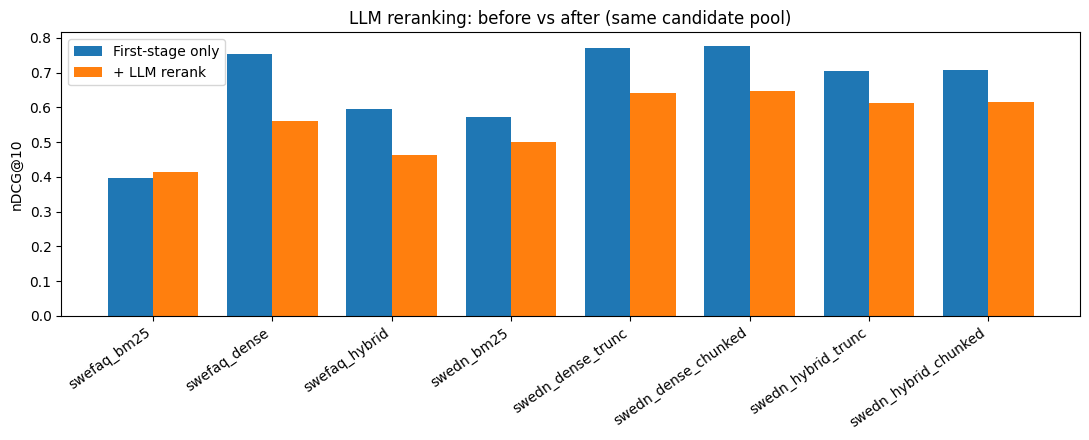

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(df)); w = 0.38
ax.bar(x - w/2, df["ndcg10_before"], w, label="First-stage only")
ax.bar(x + w/2, df["ndcg10_after"], w, label="+ LLM rerank")
ax.set_xticks(x); ax.set_xticklabels(df["name"], rotation=35, ha="right")
ax.set_ylabel("nDCG@10"); ax.set_title("LLM reranking: before vs after (same candidate pool)")
ax.legend(); plt.tight_layout()
plt.savefig(os.path.join(REPO_DIR, "results", "llm_rerank_ndcg.png"), dpi=200)
plt.show()

## 13. Example inspection (compound queries: webben, lördagar, rundgång)

In [ ]:
def find_query(queries, text):
    t = text.strip().lower()
    for q in queries:
        if q["text"].strip().lower() == t:
            return q
    print(f"NOT FOUND: {text!r}")
    return None

def show_rerank_example(q, first_stage_fn, id_to_text, qrels_dict):
    cands = first_stage_fn(q["text"], POOL_SIZE)
    texts = [id_to_text[c] for c in cands]
    full, n_valid, secs = llm_rerank_indices(q["text"], texts)
    rel = qrels_dict[q["_id"]]
    print("QUERY:", q["text"], f"| LLM valid {n_valid}/{len(cands)} | {secs:.1f}s")
    print("-- before --")
    for r, c in enumerate(cands, 1):
        print(f"  {r:2d} {'*' if c in rel else ' '} {id_to_text[c][:90]!r}")
    print("-- after --")
    for r, i in enumerate(full, 1):
        c = cands[i]
        print(f"  {r:2d} {'*' if c in rel else ' '} {id_to_text[c][:90]!r}")
    print("(* = relevant)\n")

for t in ["webben", "lördagar", "rundgång"]:
    for qs, qr, tx, fn in [(swefaq_queries, swefaq_qrels_dict, swefaq_id_to_text, swefaq_fns["swefaq_dense"]),
                           (swedn_queries, swedn_qrels_dict, swedn_id_to_text, swedn_fns["swedn_dense_trunc"])]:
        q = find_query(qs, t)
        if q is not None and q["_id"] in qr:
            show_rerank_example(q, fn, tx, qr)
            break

NOT FOUND: 'webben'
NOT FOUND: 'webben'
NOT FOUND: 'lördagar'
NOT FOUND: 'lördagar'
NOT FOUND: 'rundgång'
NOT FOUND: 'rundgång'


## 14. Limitations (report-e likhar jonno)
- LLM sudhu candidate-er **prothom `DOC_CHARS` (500) character** dekhe → lamba SwednRetrieval article-er pichoner relevant part miss hote pare (chunked first-stage-e o LLM document-er shuru dekhe, best chunk na).
- `POOL_SIZE=10` → reranker sudhu order bodlay; Recall@10 first-stage-er soman thake. Recall@1/3 ar nDCG@10 bodlay. Boro pool (20/50) alada experiment.
- Qwen2.5-1.5B chhoto model; Swedish-e weak hote pare. `pct_valid_output` check koro.
- Greedy decoding (`do_sample=False`), single run → deterministic, kintu prompt wording-er upor sensitive.
- Latency = Kaggle GPU-er per-query generate time; production GPU-te alada.